In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

print("RainRoute Data Collection Started!")

RainRoute Data Collection Started!


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import requests

print("🌧️ RainRoute Project Started!")
print("All libraries imported successfully.")

🌧️ RainRoute Project Started!
All libraries imported successfully.


In [ ]:
project_name = "RainRoute"
project_type = "Global Weather & Waterlogging Intelligence"

print("Project:", project_name)
print("Type:", project_type)

Project: RainRoute
Type: Global Weather & Waterlogging Intelligence


In [ ]:

import requests
import pandas as pd

geo_url = "https://geocoding-api.open-meteo.com/v1/search"

geo_params = {
    "name": "Vasai-Virar",
    "count": 10,
    "language": "en",
    "format": "json",
    "countryCode": "IN"
}

geo_response = requests.get(geo_url, params=geo_params)
geo_response.raise_for_status()

geo_data = geo_response.json()

print(geo_data)


{'generationtime_ms': 0.10538101}


In [ ]:
import requests

url = "https://api.open-meteo.com/v1/forecast"

params = {
    "latitude": 19.42,
    "longitude": 72.82,
    "current": "temperature_2m,relative_humidity_2m,precipitation,rain,wind_speed_10m",
    "timezone": "Asia/Kolkata"
}

response = requests.get(url, params=params)

print("Status:", response.status_code)
print("API URL:", response.url)
print("Response:", response.text)

Status: 200
API URL: https://api.open-meteo.com/v1/forecast?latitude=19.42&longitude=72.82&current=temperature_2m%2Crelative_humidity_2m%2Cprecipitation%2Crain%2Cwind_speed_10m&timezone=Asia%2FKolkata
Response: {"latitude":19.437609,"longitude":72.85715,"generationtime_ms":0.09763240814208984,"utc_offset_seconds":19800,"timezone":"Asia/Kolkata","timezone_abbreviation":"GMT+5:30","elevation":7.0,"current_units":{"time":"iso8601","interval":"seconds","temperature_2m":"°C","relative_humidity_2m":"%","precipitation":"mm","rain":"mm","wind_speed_10m":"km/h"},"current":{"time":"2026-11-02T12:15","interval":900,"temperature_2m":33.9,"relative_humidity_2m":45,"precipitation":0.00,"rain":0.00,"wind_speed_10m":3.2}}


In [ ]:

import requests
import pandas as pd

latitude = 19.437609
longitude = 72.85715

url = "https://archive-api.open-meteo.com/v1/archive"

params = {
    "latitude": latitude,
    "longitude": longitude,
    "start_date": "2024-01-01",
    "end_date": "2025-12-31",
    "hourly": [
        "temperature_2m",
        "relative_humidity_2m",
        "precipitation",
        "rain",
        "wind_speed_10m",
        "pressure_msl"
    ],
    "timezone": "Asia/Kolkata"
}

response = requests.get(url, params=params)
response.raise_for_status()

historical_data = response.json()

df = pd.DataFrame(historical_data["hourly"])

df["location"] = "Nalasopara"
df["country"] = "India"


df["time"] = pd.to_datetime(df["time"])

print("Historical dataset downloaded!")
print("Dataset shape:", df.shape)

display(df.head())


Historical dataset downloaded!
Dataset shape: (17544, 9)


,time,temperature_2m,relative_humidity_2m,precipitation,rain,wind_speed_10m,pressure_msl,location,country
0,2024-01-01 00:00:00,22.8,72,0.0,0.0,7.8,1013.1,Nalasopara,India
1,2024-01-01 01:00:00,22.4,75,0.0,0.0,6.9,1013.0,Nalasopara,India
2,2024-01-01 02:00:00,22.0,77,0.0,0.0,6.6,1012.4,Nalasopara,India
3,2024-01-01 03:00:00,21.6,79,0.0,0.0,6.5,1012.0,Nalasopara,India
4,2024-01-01 04:00:00,21.3,81,0.0,0.0,7.3,1011.8,Nalasopara,India


In [ ]:

import requests
import pandas as pd

locations = {
    "Nalasopara": {
        "latitude": 19.437609,
        "longitude": 72.85715
    },
    "Mira Road": {
        "latitude": 19.2843,
        "longitude": 72.8694
    }
}

all_data = []

for city, coordinates in locations.items():

    params = {
        "latitude": coordinates["latitude"],
        "longitude": coordinates["longitude"],
        "start_date": "2024-01-01",
        "end_date": "2025-12-31",
        "hourly": [
            "temperature_2m",
            "relative_humidity_2m",
            "precipitation",
            "rain",
            "wind_speed_10m",
            "pressure_msl"
        ],
        "timezone": "Asia/Kolkata"
    }

    url = "https://archive-api.open-meteo.com/v1/archive"

    response = requests.get(url, params=params)
    response.raise_for_status()

    city_data = response.json()

    city_df = pd.DataFrame(city_data["hourly"])

    city_df["time"] = pd.to_datetime(city_df["time"])
    city_df["location"] = city
    city_df["country"] = "India"

    all_data.append(city_df)

# Combine both locations
df = pd.concat(all_data, ignore_index=True)

print("Total records:", len(df))
print("\nLocation-wise records:")
print(df["location"].value_counts())

display(df.head())


Total records: 35088

Location-wise records:
location
Nalasopara    17544
Mira Road     17544
Name: count, dtype: int64


,time,temperature_2m,relative_humidity_2m,precipitation,rain,wind_speed_10m,pressure_msl,location,country
0,2024-01-01 00:00:00,22.8,72,0.0,0.0,7.8,1013.1,Nalasopara,India
1,2024-01-01 01:00:00,22.4,75,0.0,0.0,6.9,1013.0,Nalasopara,India
2,2024-01-01 02:00:00,22.0,77,0.0,0.0,6.6,1012.4,Nalasopara,India
3,2024-01-01 03:00:00,21.6,79,0.0,0.0,6.5,1012.0,Nalasopara,India
4,2024-01-01 04:00:00,21.3,81,0.0,0.0,7.3,1011.8,Nalasopara,India


In [ ]:

# 1. Dataset information
print("Dataset Shape:", df.shape)

print("\nMissing Values:")
print(df.isnull().sum())

# 2. Duplicate records
print("\nDuplicate Records:", df.duplicated().sum())

# 3. Rainfall summary by location
print("\nRainfall Summary:")

rainfall_summary = df.groupby("location").agg(
    total_rainfall=("precipitation", "sum"),
    average_rainfall=("precipitation", "mean"),
    maximum_rainfall=("precipitation", "max"),
    rainy_hours=("rain", lambda x: (x > 0).sum())
)

display(rainfall_summary)


Dataset Shape: (35088, 9)

Missing Values:
time                    0
temperature_2m          0
relative_humidity_2m    0
precipitation           0
rain                    0
wind_speed_10m          0
pressure_msl            0
location                0
country                 0
dtype: int64

Duplicate Records: 0

Rainfall Summary:


,total_rainfall,average_rainfall,maximum_rainfall,rainy_hours
location,,,,
Mira Road,5021.0,0.286195,24.8,5236
Nalasopara,4629.5,0.263879,24.5,4981


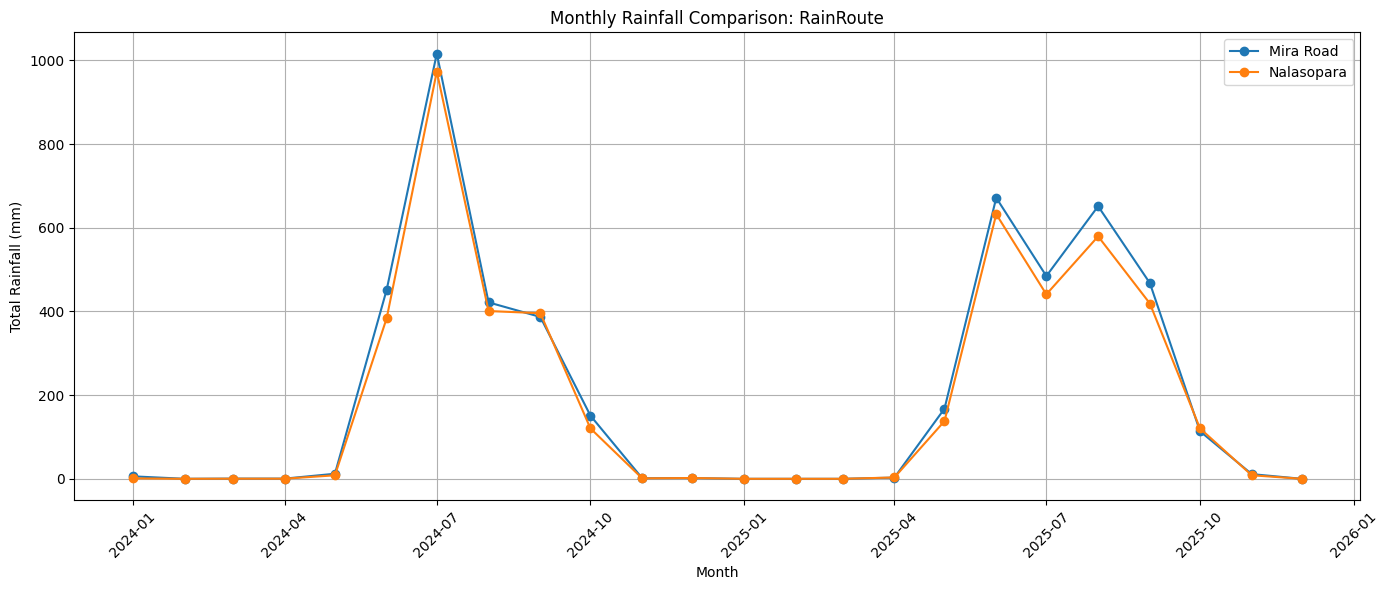

In [ ]:

import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# Convert time into datetime
df["time"] = pd.to_datetime(df["time"])

# Extract month
df["month"] = df["time"].dt.to_period("M").dt.to_timestamp()

# Calculate monthly rainfall
monthly_rainfall = (
    df.groupby(["month", "location"])["precipitation"]
    .sum()
    .unstack(fill_value=0)
)

# Plot graph
plt.figure(figsize=(14, 6))

for city in monthly_rainfall.columns:
    plt.plot(
        monthly_rainfall.index,
        monthly_rainfall[city],
        marker="o",
        label=city
    )

plt.title("Monthly Rainfall Comparison: RainRoute")
plt.xlabel("Month")
plt.ylabel("Total Rainfall (mm)")
plt.legend()
plt.grid(True)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


In [ ]:
# Extract year and month
df["year"] = df["time"].dt.year
df["month_name"] = df["time"].dt.month_name()

# Calculate monthly rainfall
monthly_summary = (
    df.groupby(["location", "year", "month_name"])["precipitation"]
    .sum()
    .reset_index()
)

# Display results
monthly_summary.head(15)

,location,year,month_name,precipitation
0,Mira Road,2024,April,0.5
1,Mira Road,2024,August,421.7
2,Mira Road,2024,December,1.7
3,Mira Road,2024,February,0.1
4,Mira Road,2024,January,5.9
5,Mira Road,2024,July,1016.3
6,Mira Road,2024,June,452.1
7,Mira Road,2024,March,0.5
8,Mira Road,2024,May,12.1
9,Mira Road,2024,November,1.4


In [ ]:
highest_rainfall = monthly_summary.loc[
    monthly_summary.groupby("location")["precipitation"].idxmax()
]

print("Highest Rainfall Month:")
display(highest_rainfall)

Highest Rainfall Month:


,location,year,month_name,precipitation
5,Mira Road,2024,July,1016.3
29,Nalasopara,2024,July,973.2


In [ ]:
global_locations = {
    "Nalasopara": {
        "latitude": 19.437609,
        "longitude": 72.85715,
        "country": "India"
    },
    "Mira Road": {
        "latitude": 19.2843,
        "longitude": 72.8694,
        "country": "India"
    },
    "London": {
        "latitude": 51.5072,
        "longitude": -0.1276,
        "country": "United Kingdom"
    },
    "New York": {
        "latitude": 40.7128,
        "longitude": -74.0060,
        "country": "USA"
    },
    "Tokyo": {
        "latitude": 35.6762,
        "longitude": 139.6503,
        "country": "Japan"
    },
    "Sydney": {
        "latitude": -33.8688,
        "longitude": 151.2093,
        "country": "Australia"
    }
}

print("Total Locations:", len(global_locations))

Total Locations: 6


In [ ]:
import requests
import pandas as pd

all_global_data = []

for city, details in global_locations.items():

    print("Collecting data for:", city)

    params = {
        "latitude": details["latitude"],
        "longitude": details["longitude"],
        "start_date": "2024-01-01",
        "end_date": "2025-12-31",
        "hourly": [
            "temperature_2m",
            "relative_humidity_2m",
            "precipitation",
            "rain",
            "wind_speed_10m",
            "pressure_msl"
        ],
        "timezone": "auto"
    }

    url = "https://archive-api.open-meteo.com/v1/archive"

    response = requests.get(url, params=params)
    response.raise_for_status()

    weather_data = response.json()

    city_df = pd.DataFrame(weather_data["hourly"])

    city_df["time"] = pd.to_datetime(city_df["time"])
    city_df["location"] = city
    city_df["country"] = details["country"]

    all_global_data.append(city_df)

# Combine all locations
global_df = pd.concat(all_global_data, ignore_index=True)

print("\nGlobal Dataset Created!")
print("Total Records:", len(global_df))

display(global_df.head())


Global Dataset Created!
Total Records: 105264


,time,temperature_2m,relative_humidity_2m,precipitation,rain,wind_speed_10m,pressure_msl,location,country
0,2024-01-01 00:00:00,22.8,72,0.0,0.0,7.8,1013.1,Nalasopara,India
1,2024-01-01 01:00:00,22.4,75,0.0,0.0,6.9,1013.0,Nalasopara,India
2,2024-01-01 02:00:00,22.0,77,0.0,0.0,6.6,1012.4,Nalasopara,India
3,2024-01-01 03:00:00,21.6,79,0.0,0.0,6.5,1012.0,Nalasopara,India
4,2024-01-01 04:00:00,21.3,81,0.0,0.0,7.3,1011.8,Nalasopara,India


In [ ]:
# 1. Dataset shape
print("Dataset Shape:", global_df.shape)

# 2. Missing values
print("\nMissing Values:")
print(global_df.isnull().sum())

# 3. Duplicate records
print("\nDuplicate Records:", global_df.duplicated().sum())

# 4. Country-wise records
print("\nCountry-wise Records:")
print(global_df.groupby("country").size())

# 5. Location-wise records
print("\nLocation-wise Records:")
print(global_df.groupby("location").size())

# 6. Date range
print("\nDate Range:")
print("Start:", global_df["time"].min())
print("End:", global_df["time"].max())

Dataset Shape: (105264, 9)

Missing Values:
time                    0
temperature_2m          0
relative_humidity_2m    0
precipitation           0
rain                    0
wind_speed_10m          0
pressure_msl            0
location                0
country                 0
dtype: int64

Duplicate Records: 0

Country-wise Records:
country
Australia         17544
India             35088
Japan             17544
USA               17544
United Kingdom    17544
dtype: int64

Location-wise Records:
location
London        17544
Mira Road     17544
Nalasopara    17544
New York      17544
Sydney        17544
Tokyo         17544
dtype: int64

Date Range:
Start: 2024-01-01 00:00:00
End: 2025-12-31 23:00:00


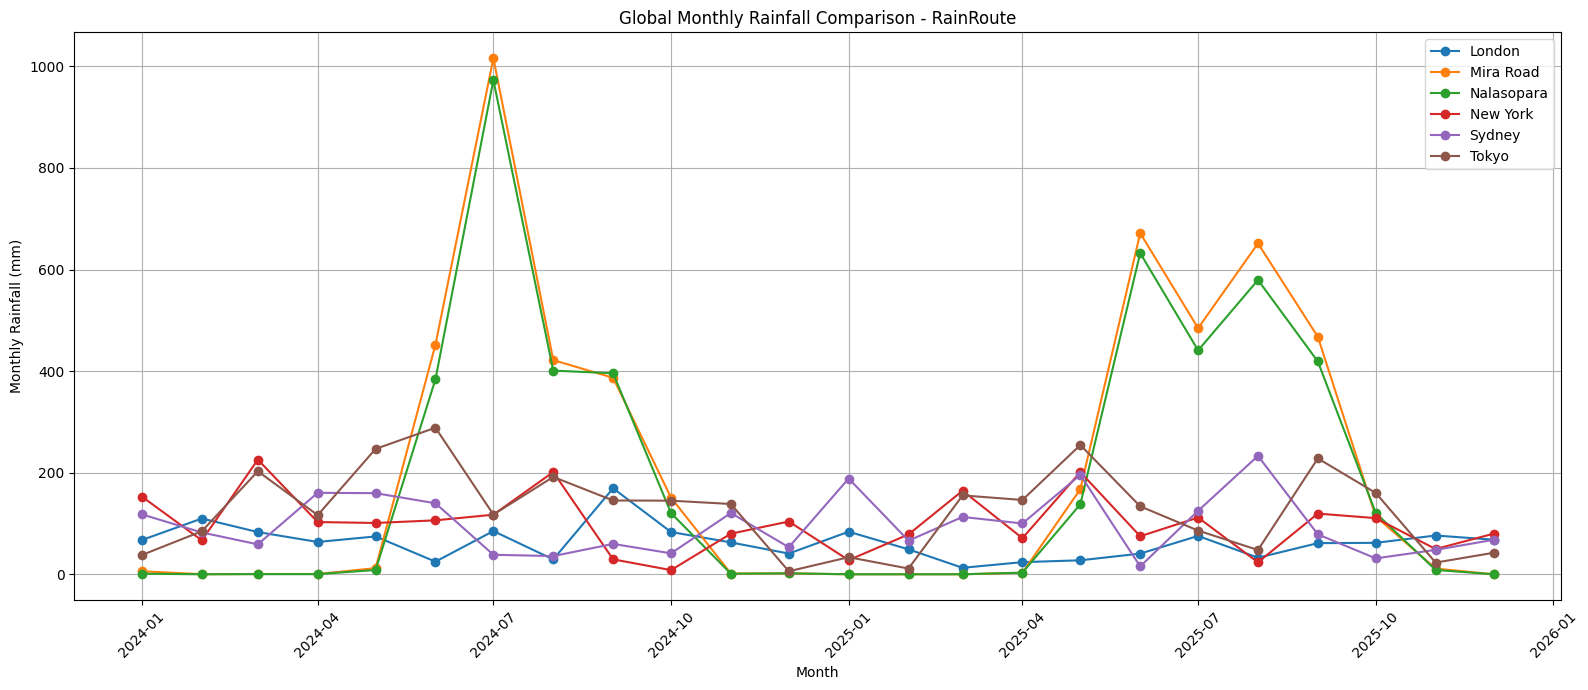

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd

# Create monthly column
global_df["month"] = (
    global_df["time"].dt.to_period("M").dt.to_timestamp()
)

# Calculate monthly rainfall for each location
monthly_global = (
    global_df.groupby(["month", "location"])["precipitation"]
    .sum()
    .unstack(fill_value=0)
)

# Create comparison graph
plt.figure(figsize=(16, 7))

for city in monthly_global.columns:
    plt.plot(
        monthly_global.index,
        monthly_global[city],
        marker="o",
        label=city
    )

plt.title("Global Monthly Rainfall Comparison - RainRoute")
plt.xlabel("Month")
plt.ylabel("Monthly Rainfall (mm)")
plt.legend()
plt.grid(True)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

Country-wise Rainfall Analysis

In [ ]:
country_rainfall = (
    global_df.groupby("country")
    .agg(
        total_rainfall=("precipitation", "sum"),
        average_rainfall=("precipitation", "mean"),
        maximum_rainfall=("precipitation", "max"),
        rainy_hours=("rain", lambda x: (x > 0).sum())
    )
    .reset_index()
)

country_rainfall = country_rainfall.round(2)

display(country_rainfall)

,country,total_rainfall,average_rainfall,maximum_rainfall,rainy_hours
0,Australia,2330.9,0.13,12.2,3601
1,India,9650.5,0.28,24.8,10217
2,Japan,3043.4,0.17,21.8,2840
3,USA,2408.0,0.14,19.8,2313
4,United Kingdom,1507.0,0.09,9.7,2760


Create Bar Chart

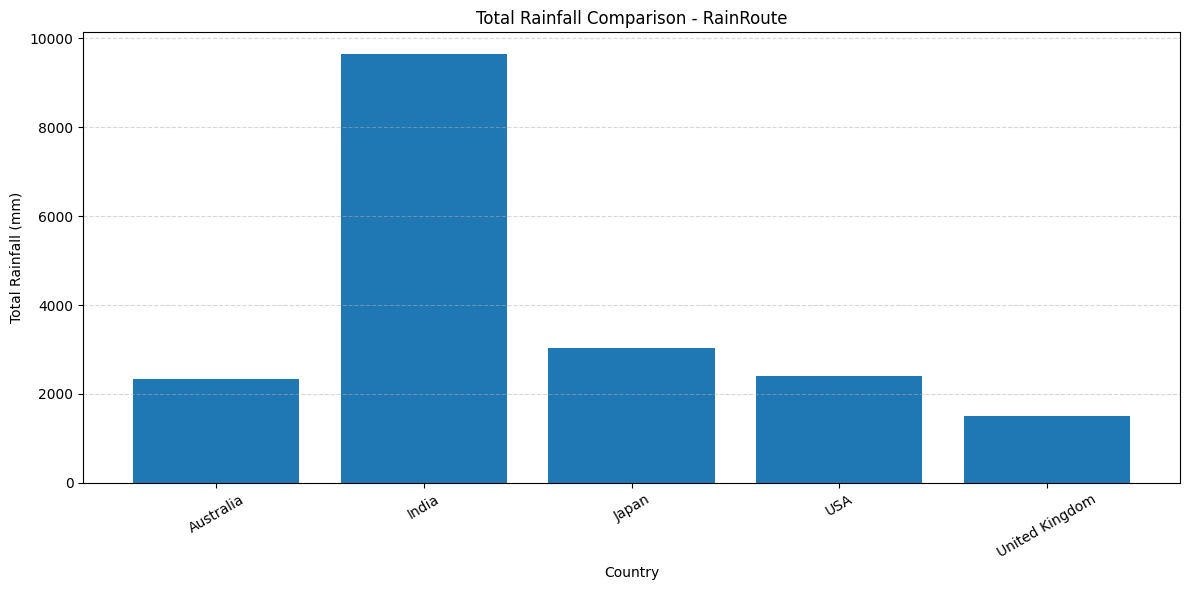

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))

plt.bar(
    country_rainfall["country"],
    country_rainfall["total_rainfall"]
)

plt.title("Total Rainfall Comparison - RainRoute")
plt.xlabel("Country")
plt.ylabel("Total Rainfall (mm)")

plt.xticks(rotation=30)
plt.grid(axis="y", linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()

Create Rainfall Categories

In [ ]:
def classify_rainfall(value):

    if value == 0:
        return "No Rain"

    elif value <= 2.5:
        return "Light Rain"

    elif value <= 7.5:
        return "Moderate Rain"

    else:
        return "Heavy Rain"


global_df["rainfall_category"] = (
    global_df["precipitation"].apply(classify_rainfall)
)

print("Rainfall Categories Created!")

display(global_df[
    ["location", "country", "precipitation", "rainfall_category"]
].head(15))

Rainfall Categories Created!


,location,country,precipitation,rainfall_category
0,Nalasopara,India,0.0,No Rain
1,Nalasopara,India,0.0,No Rain
2,Nalasopara,India,0.0,No Rain
3,Nalasopara,India,0.0,No Rain
4,Nalasopara,India,0.0,No Rain
5,Nalasopara,India,0.0,No Rain
6,Nalasopara,India,0.0,No Rain
7,Nalasopara,India,0.0,No Rain
8,Nalasopara,India,0.0,No Rain
9,Nalasopara,India,0.0,No Rain


all location

In [ ]:
print("All Locations:")
print(global_df["location"].unique())

print("\nTotal Records:")
print(global_df.groupby("location").size())

All Locations:
['Nalasopara' 'Mira Road' 'London' 'New York' 'Tokyo' 'Sydney']

Total Records:
location
London        17544
Mira Road     17544
Nalasopara    17544
New York      17544
Sydney        17544
Tokyo         17544
dtype: int64


Check rainfall categories for all cities

In [ ]:
display(
    global_df.groupby(
        ["location", "rainfall_category"]
    ).size().unstack(fill_value=0)
)


rainfall_category,Heavy Rain,Light Rain,Moderate Rain,No Rain
location,,,,
London,3,2672,89,14780
Mira Road,72,4750,414,12308
Nalasopara,59,4538,384,12563
New York,33,2273,205,15033
Sydney,13,3403,185,13943
Tokyo,44,2545,259,14696


In [ ]:
global_df.to_csv(
    "RainRoute_Global_Weather.csv",
    index=False
)

print("RainRoute Dataset Saved Successfully!")
print("Total Records:", len(global_df))

RainRoute Dataset Saved Successfully!
Total Records: 105264


In [ ]:
from google.colab import files

files.download("RainRoute_Global_Weather.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
# Extract date and time features

global_df["year"] = global_df["time"].dt.year
global_df["month"] = global_df["time"].dt.month
global_df["day"] = global_df["time"].dt.day
global_df["hour"] = global_df["time"].dt.hour
global_df["day_of_week"] = global_df["time"].dt.dayofweek

# Create season column
def get_season(month):
    if month in [12, 1, 2]:
        return "Winter"
    elif month in [3, 4, 5]:
        return "Summer"
    elif month in [6, 7, 8, 9]:
        return "Monsoon"
    else:
        return "Autumn"

global_df["season"] = global_df["month"].apply(get_season)

print("Feature Engineering Completed!")

display(global_df.head())

Feature Engineering Completed!


,time,temperature_2m,relative_humidity_2m,precipitation,rain,wind_speed_10m,pressure_msl,location,country,month,rainfall_category,year,day,hour,day_of_week,season
0,2024-01-01 00:00:00,22.8,72,0.0,0.0,7.8,1013.1,Nalasopara,India,1,No Rain,2024,1,0,0,Winter
1,2024-01-01 01:00:00,22.4,75,0.0,0.0,6.9,1013.0,Nalasopara,India,1,No Rain,2024,1,1,0,Winter
2,2024-01-01 02:00:00,22.0,77,0.0,0.0,6.6,1012.4,Nalasopara,India,1,No Rain,2024,1,2,0,Winter
3,2024-01-01 03:00:00,21.6,79,0.0,0.0,6.5,1012.0,Nalasopara,India,1,No Rain,2024,1,3,0,Winter
4,2024-01-01 04:00:00,21.3,81,0.0,0.0,7.3,1011.8,Nalasopara,India,1,No Rain,2024,1,4,0,Winter


Create Previous Rainfall Features

In [ ]:
# Sort data by location and time
global_df = global_df.sort_values(
    ["location", "time"]
).copy()

# Previous hour rainfall
global_df["rain_previous_hour"] = (
    global_df.groupby("location")["precipitation"].shift(1)
)

# Previous 3 hours total rainfall
global_df["rain_last_3_hours"] = (
    global_df.groupby("location")["precipitation"]
    .transform(lambda x: x.shift(1).rolling(3).sum())
)

# Previous 6 hours total rainfall
global_df["rain_last_6_hours"] = (
    global_df.groupby("location")["precipitation"]
    .transform(lambda x: x.shift(1).rolling(6).sum())
)

print("Rainfall Lag Features Created!")

display(
    global_df[
        [
            "location",
            "time",
            "precipitation",
            "rain_previous_hour",
            "rain_last_3_hours",
            "rain_last_6_hours"
        ]
    ].head(15)
)

Rainfall Lag Features Created!


,location,time,precipitation,rain_previous_hour,rain_last_3_hours,rain_last_6_hours
35088,London,2024-01-01 00:00:00,0.0,NaN,NaN,NaN
35089,London,2024-01-01 01:00:00,0.0,0.0,NaN,NaN
35090,London,2024-01-01 02:00:00,0.0,0.0,NaN,NaN
35091,London,2024-01-01 03:00:00,0.0,0.0,0.0,NaN
35092,London,2024-01-01 04:00:00,0.0,0.0,0.0,NaN
35093,London,2024-01-01 05:00:00,0.0,0.0,0.0,NaN
35094,London,2024-01-01 06:00:00,0.0,0.0,0.0,0.0
35095,London,2024-01-01 07:00:00,0.0,0.0,0.0,0.0
35096,London,2024-01-01 08:00:00,0.0,0.0,0.0,0.0
35097,London,2024-01-01 09:00:00,0.0,0.0,0.0,0.0


Prepare ML Dataset

In [ ]:
# Check all columns
print("Total Features:", len(global_df.columns))

print("\nAll Columns:")
print(global_df.columns.tolist())

# Check missing values
print("\nMissing Values:")
print(global_df.isnull().sum())

# Remove rows where previous rainfall is unavailable
ml_df = global_df.dropna().copy()

print("\nML Dataset Shape:", ml_df.shape)

display(ml_df.head())

Total Features: 19

All Columns:
['time', 'temperature_2m', 'relative_humidity_2m', 'precipitation', 'rain', 'wind_speed_10m', 'pressure_msl', 'location', 'country', 'month', 'rainfall_category', 'year', 'day', 'hour', 'day_of_week', 'season', 'rain_previous_hour', 'rain_last_3_hours', 'rain_last_6_hours']

Missing Values:
time                     0
temperature_2m           0
relative_humidity_2m     0
precipitation            0
rain                     0
wind_speed_10m           0
pressure_msl             0
location                 0
country                  0
month                    0
rainfall_category        0
year                     0
day                      0
hour                     0
day_of_week              0
season                   0
rain_previous_hour       6
rain_last_3_hours       18
rain_last_6_hours       36
dtype: int64

ML Dataset Shape: (105228, 19)


,time,temperature_2m,relative_humidity_2m,precipitation,rain,wind_speed_10m,pressure_msl,location,country,month,rainfall_category,year,day,hour,day_of_week,season,rain_previous_hour,rain_last_3_hours,rain_last_6_hours
35094,2024-01-01 06:00:00,6.5,74,0.0,0.0,24.9,1000.6,London,United Kingdom,1,No Rain,2024,1,6,0,Winter,0.0,0.0,0.0
35095,2024-01-01 07:00:00,6.2,71,0.0,0.0,22.9,1001.7,London,United Kingdom,1,No Rain,2024,1,7,0,Winter,0.0,0.0,0.0
35096,2024-01-01 08:00:00,5.9,71,0.0,0.0,19.6,1002.7,London,United Kingdom,1,No Rain,2024,1,8,0,Winter,0.0,0.0,0.0
35097,2024-01-01 09:00:00,6.3,69,0.0,0.0,19.3,1003.5,London,United Kingdom,1,No Rain,2024,1,9,0,Winter,0.0,0.0,0.0
35098,2024-01-01 10:00:00,7.0,69,0.0,0.0,19.1,1003.9,London,United Kingdom,1,No Rain,2024,1,10,0,Winter,0.0,0.0,0.0


Create Next-Hour Rainfall Target

In [ ]:
# Sort data by location and time
ml_df = ml_df.sort_values(
    ["location", "time"]
).copy()

# Create next-hour rainfall target
ml_df["next_hour_rainfall"] = (
    ml_df.groupby("location")["precipitation"].shift(-1)
)

print("Prediction Target Created!")

display(
    ml_df[
        [
            "location",
            "time",
            "precipitation",
            "rain_previous_hour",
            "rain_last_3_hours",
            "next_hour_rainfall"
        ]
    ].head(15)
)

Prediction Target Created!


,location,time,precipitation,rain_previous_hour,rain_last_3_hours,next_hour_rainfall
35094,London,2024-01-01 06:00:00,0.0,0.0,0.0,0.0
35095,London,2024-01-01 07:00:00,0.0,0.0,0.0,0.0
35096,London,2024-01-01 08:00:00,0.0,0.0,0.0,0.0
35097,London,2024-01-01 09:00:00,0.0,0.0,0.0,0.0
35098,London,2024-01-01 10:00:00,0.0,0.0,0.0,0.0
35099,London,2024-01-01 11:00:00,0.0,0.0,0.0,0.0
35100,London,2024-01-01 12:00:00,0.0,0.0,0.0,0.0
35101,London,2024-01-01 13:00:00,0.0,0.0,0.0,0.0
35102,London,2024-01-01 14:00:00,0.0,0.0,0.0,0.5
35103,London,2024-01-01 15:00:00,0.5,0.0,0.0,0.1


In [ ]:
print("Locations in ML Dataset:")
print(ml_df["location"].unique())

print("\nLocation-wise Records:")
print(ml_df.groupby("location").size())

Locations in ML Dataset:
['London' 'Mira Road' 'Nalasopara' 'New York' 'Sydney' 'Tokyo']

Location-wise Records:
location
London        17538
Mira Road     17538
Nalasopara    17538
New York      17538
Sydney        17538
Tokyo         17538
dtype: int64


In [ ]:
display(
    ml_df.groupby("location").head(2)
    [["location", "time", "precipitation", "next_hour_rainfall"]]
)

,location,time,precipitation,next_hour_rainfall
35094,London,2024-01-01 06:00:00,0.0,0.0
35095,London,2024-01-01 07:00:00,0.0,0.0
17550,Mira Road,2024-01-01 06:00:00,0.0,0.0
17551,Mira Road,2024-01-01 07:00:00,0.0,0.0
6,Nalasopara,2024-01-01 06:00:00,0.0,0.0
7,Nalasopara,2024-01-01 07:00:00,0.0,0.0
52638,New York,2024-01-01 06:00:00,0.0,0.0
52639,New York,2024-01-01 07:00:00,0.0,0.0
87726,Sydney,2024-01-01 06:00:00,0.0,0.0
87727,Sydney,2024-01-01 07:00:00,0.0,0.1


In [ ]:
from sklearn.model_selection import train_test_split

# Remove rows where target is missing
ml_df = ml_df.dropna(subset=["next_hour_rainfall"]).copy()

# Input features
features = [
    "temperature_2m",
    "relative_humidity_2m",
    "wind_speed_10m",
    "pressure_msl",
    "month",
    "hour",
    "rain_previous_hour",
    "rain_last_3_hours",
    "rain_last_6_hours"
]

X = ml_df[features]
y = ml_df["next_hour_rainfall"]

# Time-based 80:20 split
split_index = int(len(ml_df) * 0.80)

X_train = X.iloc[:split_index]
X_test = X.iloc[split_index:]

y_train = y.iloc[:split_index]
y_test = y.iloc[split_index:]

print("Training Records:", len(X_train))
print("Testing Records:", len(X_test))

print("Training Shape:", X_train.shape)
print("Testing Shape:", X_test.shape)

Training Records: 84177
Testing Records: 21045
Training Shape: (84177, 9)
Testing Shape: (21045, 9)


In [ ]:
# Prepare data location-wise
work_df = global_df.sort_values(["location", "time"]).copy()

# Predict next hour rainfall
work_df["next_hour_rainfall"] = (
    work_df.groupby("location")["precipitation"].shift(-1)
)

# Remove rows with missing lag features or target
work_df = work_df.dropna(
    subset=[
        "rain_previous_hour",
        "rain_last_3_hours",
        "rain_last_6_hours",
        "next_hour_rainfall"
    ]
).copy()

features = [
    "temperature_2m",
    "relative_humidity_2m",
    "wind_speed_10m",
    "pressure_msl",
    "month",
    "hour",
    "rain_previous_hour",
    "rain_last_3_hours",
    "rain_last_6_hours"
]

train_parts = []
test_parts = []

# Split each location chronologically
for city, city_data in work_df.groupby("location"):
    city_data = city_data.sort_values("time")

    split_index = int(len(city_data) * 0.80)

    train_parts.append(city_data.iloc[:split_index])
    test_parts.append(city_data.iloc[split_index:])

train_df = pd.concat(train_parts)
test_df = pd.concat(test_parts)

X_train = train_df[features]
y_train = train_df["next_hour_rainfall"]

X_test = test_df[features]
y_test = test_df["next_hour_rainfall"]

print("Training Records:", len(X_train))
print("Testing Records:", len(X_test))

print("\nTraining Locations:")
print(train_df["location"].value_counts())

print("\nTesting Locations:")
print(test_df["location"].value_counts())

Training Records: 84174
Testing Records: 21048

Training Locations:
location
London        14029
Mira Road     14029
Nalasopara    14029
New York      14029
Sydney        14029
Tokyo         14029
Name: count, dtype: int64

Testing Locations:
location
London        3508
Mira Road     3508
Nalasopara    3508
New York      3508
Sydney        3508
Tokyo         3508
Name: count, dtype: int64


In [ ]:
from sklearn.ensemble import RandomForestRegressor

# Create model
model = RandomForestRegressor(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

# Train model
model.fit(X_train, y_train)

print("RainRoute Random Forest Model Trained Successfully!")

RainRoute Random Forest Model Trained Successfully!


In [ ]:
import numpy as np
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Predict rainfall
y_pred = model.predict(X_test)

# Calculate evaluation metrics
mae = mean_absolute_error(y_test, y_pred)

mse = mean_squared_error(y_test, y_pred)

rmse = np.sqrt(mse)

r2 = r2_score(y_test, y_pred)

print("RAINROUTE MODEL EVALUATION")
print("--------------------------")
print("MAE:", round(mae, 3))
print("MSE:", round(mse, 3))
print("RMSE:", round(rmse, 3))
print("R2 Score:", round(r2, 3))

RAINROUTE MODEL EVALUATION
--------------------------
MAE: 0.215
MSE: 0.549
RMSE: 0.741
R2 Score: 0.293


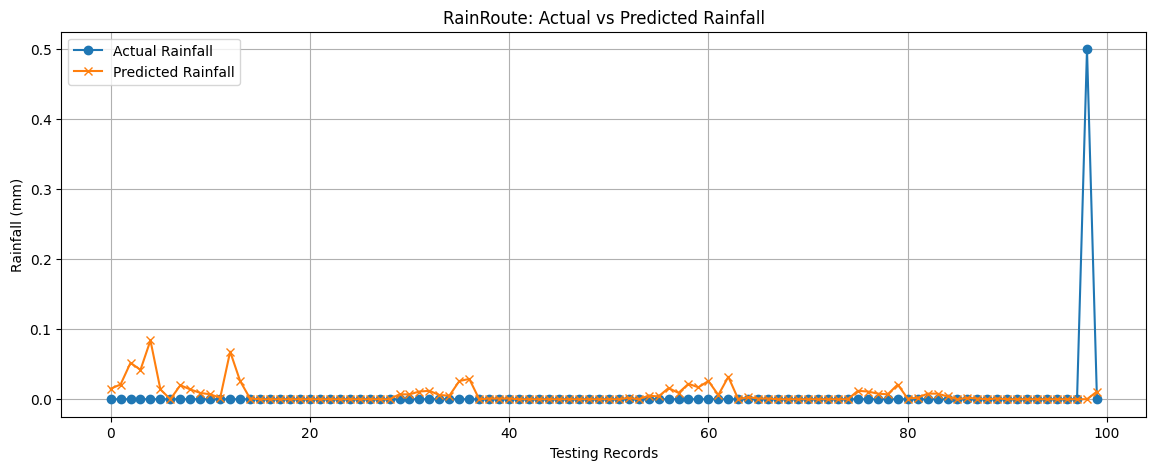

In [ ]:
import matplotlib.pyplot as plt

# Select first 100 testing records
plt.figure(figsize=(14, 5))

plt.plot(
    y_test.iloc[:100].values,
    label="Actual Rainfall",
    marker="o"
)

plt.plot(
    y_pred[:100],
    label="Predicted Rainfall",
    marker="x"
)

plt.title("RainRoute: Actual vs Predicted Rainfall")
plt.xlabel("Testing Records")
plt.ylabel("Rainfall (mm)")
plt.legend()
plt.grid(True)

plt.show()

In [ ]:
import joblib
import os

# Create models folder
os.makedirs("models", exist_ok=True)

# Save trained model
joblib.dump(model, "models/rainroute_model.pkl")

print("RainRoute Model Saved Successfully!")

RainRoute Model Saved Successfully!


In [ ]:
from google.colab import files

files.download("models/rainroute_model.pkl")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import joblib

# Load saved model
loaded_model = joblib.load("models/rainroute_model.pkl")

# Test prediction
sample_prediction = loaded_model.predict(X_test.iloc[:5])

print("Next Hour Rainfall Predictions:")
print(sample_prediction)

Next Hour Rainfall Predictions:
[0.015 0.021 0.052 0.042 0.084]


,Feature,Importance
6,rain_previous_hour,0.308614
2,wind_speed_10m,0.117722
3,pressure_msl,0.115366
0,temperature_2m,0.102197
1,relative_humidity_2m,0.082459
7,rain_last_3_hours,0.081955
8,rain_last_6_hours,0.081448
5,hour,0.068995
4,month,0.041245


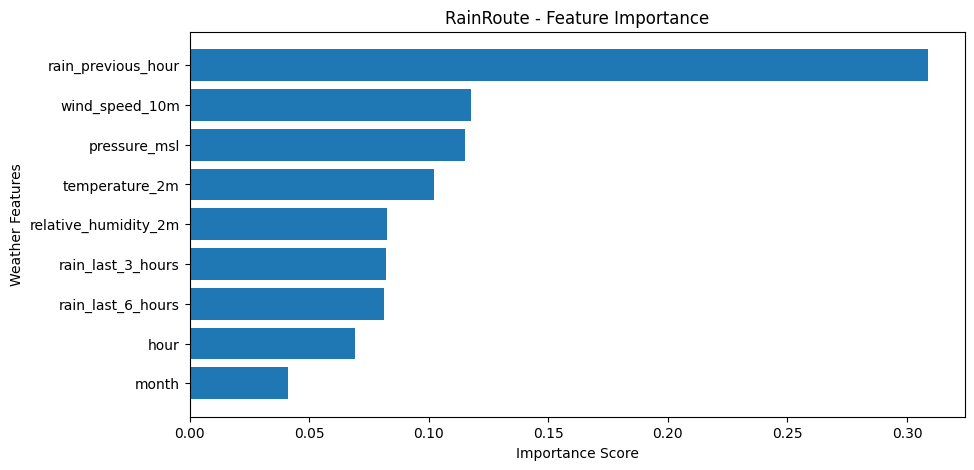

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

importance_df = pd.DataFrame({
    "Feature": features,
    "Importance": model.feature_importances_
})

importance_df = importance_df.sort_values(
    by="Importance",
    ascending=False
)

display(importance_df)

plt.figure(figsize=(10, 5))
plt.barh(
    importance_df["Feature"],
    importance_df["Importance"]
)

plt.title("RainRoute - Feature Importance")
plt.xlabel("Importance Score")
plt.ylabel("Weather Features")
plt.gca().invert_yaxis()
plt.show()

In [ ]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np
import pandas as pd

# Store predictions in testing dataset
test_results = test_df.copy()
test_results["predicted_rainfall"] = model.predict(X_test)

# Calculate metrics for each location
location_results = []

for city, data in test_results.groupby("location"):

    actual = data["next_hour_rainfall"]
    predicted = data["predicted_rainfall"]

    location_results.append({
        "Location": city,
        "MAE": mean_absolute_error(actual, predicted),
        "RMSE": np.sqrt(mean_squared_error(actual, predicted)),
        "R2 Score": r2_score(actual, predicted)
    })

location_metrics = pd.DataFrame(location_results)

location_metrics = location_metrics.round(3)

display(location_metrics)

,Location,MAE,RMSE,R2 Score
0,London,0.188,0.433,-0.349
1,Mira Road,0.323,1.083,0.355
2,Nalasopara,0.304,0.967,0.340
3,New York,0.135,0.537,0.193
4,Sydney,0.145,0.442,0.238
5,Tokyo,0.196,0.718,0.150


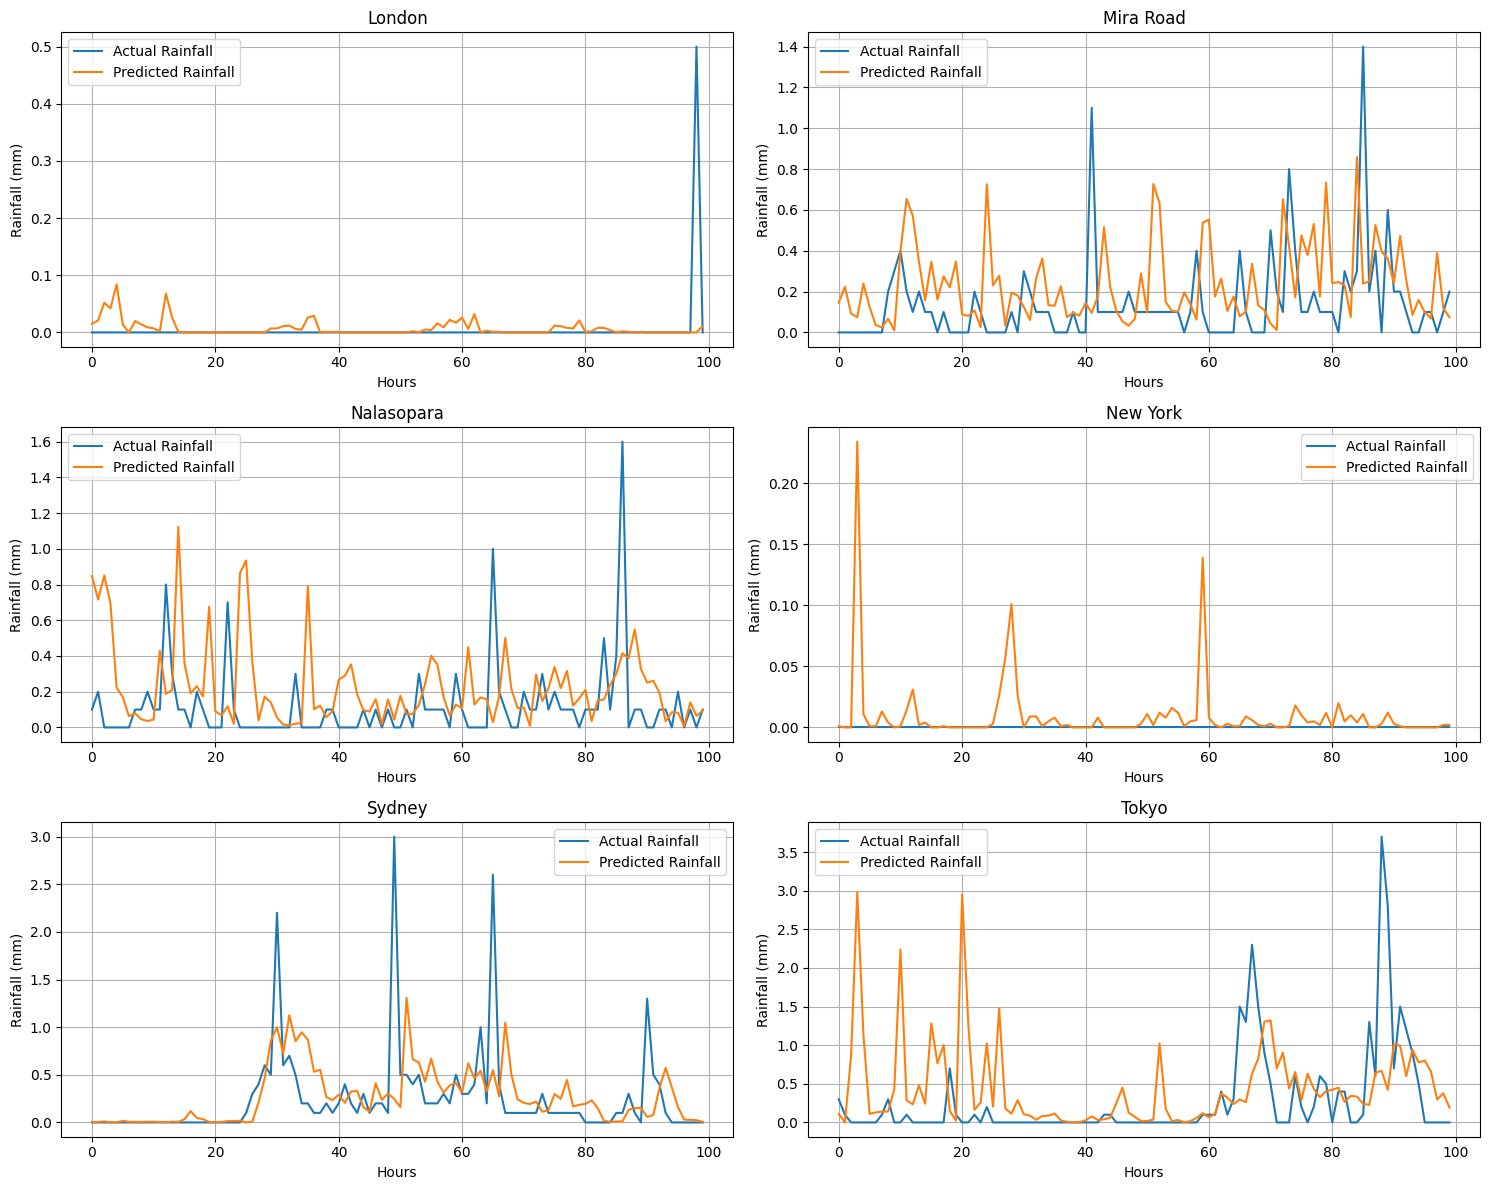

In [ ]:
import matplotlib.pyplot as plt

locations = test_results["location"].unique()

fig, axes = plt.subplots(3, 2, figsize=(15, 12))
axes = axes.flatten()

for i, city in enumerate(locations):

    city_data = test_results[
        test_results["location"] == city
    ].head(100)

    axes[i].plot(
        city_data["next_hour_rainfall"].values,
        label="Actual Rainfall"
    )

    axes[i].plot(
        city_data["predicted_rainfall"].values,
        label="Predicted Rainfall"
    )

    axes[i].set_title(city)
    axes[i].set_xlabel("Hours")
    axes[i].set_ylabel("Rainfall (mm)")
    axes[i].legend()
    axes[i].grid(True)

plt.tight_layout()
plt.show()

In [ ]:
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# Create baseline model
baseline_model = DummyRegressor(strategy="mean")

# Train baseline model
baseline_model.fit(X_train, y_train)

# Predict rainfall
baseline_pred = baseline_model.predict(X_test)

# Evaluate baseline
baseline_mae = mean_absolute_error(y_test, baseline_pred)
baseline_rmse = np.sqrt(mean_squared_error(y_test, baseline_pred))
baseline_r2 = r2_score(y_test, baseline_pred)

print("BASELINE MODEL RESULTS")
print("----------------------")
print("MAE:", round(baseline_mae, 3))
print("RMSE:", round(baseline_rmse, 3))
print("R2 Score:", round(baseline_r2, 3))

BASELINE MODEL RESULTS
----------------------
MAE: 0.298
RMSE: 0.881
R2 Score: -0.0


In [ ]:
comparison = pd.DataFrame({
    "Model": ["Baseline", "Random Forest"],
    "MAE": [
        baseline_mae,
        mean_absolute_error(y_test, y_pred)
    ],
    "RMSE": [
        baseline_rmse,
        np.sqrt(mean_squared_error(y_test, y_pred))
    ],
    "R2 Score": [
        baseline_r2,
        r2_score(y_test, y_pred)
    ]
})

comparison = comparison.round(3)

display(comparison)

,Model,MAE,RMSE,R2 Score
0,Baseline,0.298,0.881,-0.000
1,Random Forest,0.215,0.741,0.293


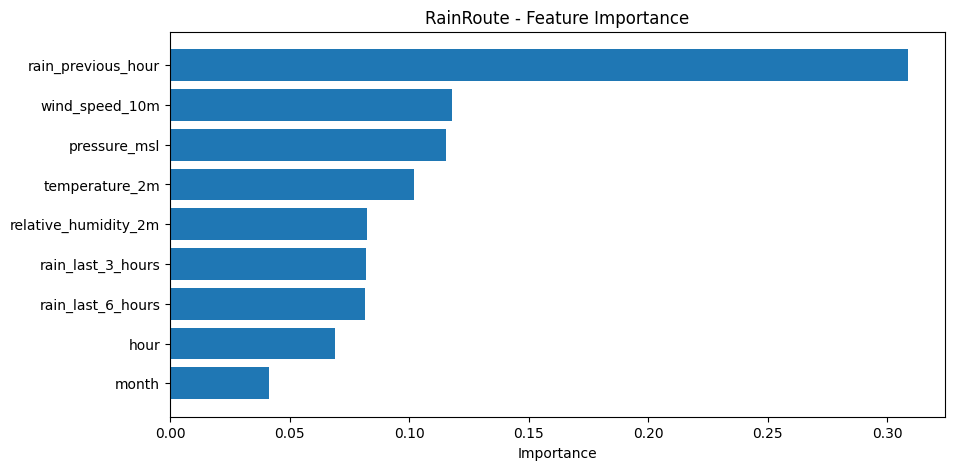

In [ ]:
importance_df = pd.DataFrame({
    "Feature": features,
    "Importance": model.feature_importances_
})

importance_df = importance_df.sort_values(
    "Importance",
    ascending=False
)

plt.figure(figsize=(10, 5))

plt.barh(
    importance_df["Feature"],
    importance_df["Importance"]
)

plt.title("RainRoute - Feature Importance")
plt.xlabel("Importance")
plt.gca().invert_yaxis()
plt.show()

In [ ]:
features = [
    "temperature_2m",
    "relative_humidity_2m",
    "wind_speed_10m",
    "pressure_msl",
    "month",
    "hour",
    "rain_previous_hour",
    "rain_last_3_hours",
    "rain_last_6_hours"
]

print("Features created successfully!")
print(features)

Features created successfully!
['temperature_2m', 'relative_humidity_2m', 'wind_speed_10m', 'pressure_msl', 'month', 'hour', 'rain_previous_hour', 'rain_last_3_hours', 'rain_last_6_hours']


Feature Importance Analysis

,Feature,Importance
6,rain_previous_hour,0.308614
2,wind_speed_10m,0.117722
3,pressure_msl,0.115366
0,temperature_2m,0.102197
1,relative_humidity_2m,0.082459
7,rain_last_3_hours,0.081955
8,rain_last_6_hours,0.081448
5,hour,0.068995
4,month,0.041245


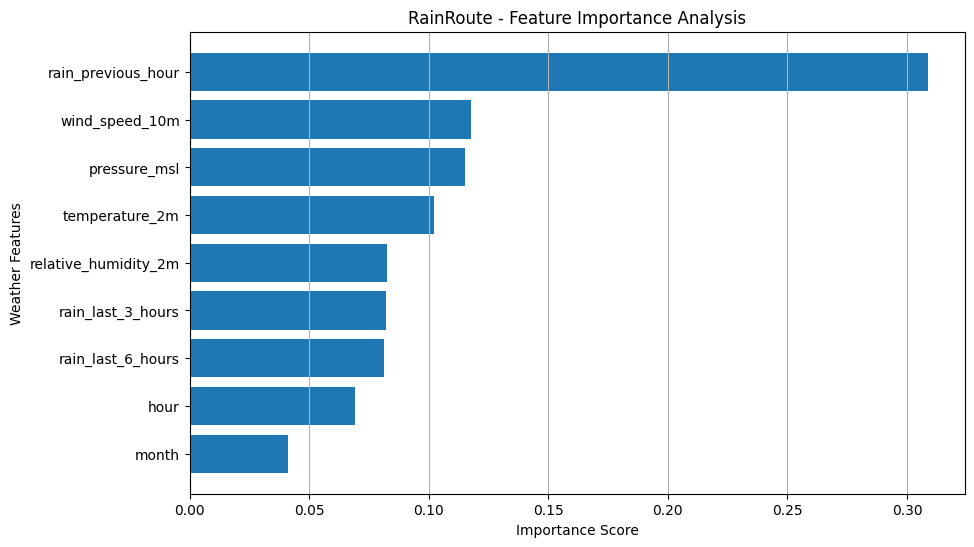

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

# Define model features
features = [
    "temperature_2m",
    "relative_humidity_2m",
    "wind_speed_10m",
    "pressure_msl",
    "month",
    "hour",
    "rain_previous_hour",
    "rain_last_3_hours",
    "rain_last_6_hours"
]

# Calculate feature importance
importance_df = pd.DataFrame({
    "Feature": features,
    "Importance": model.feature_importances_
})

# Sort features
importance_df = importance_df.sort_values(
    by="Importance",
    ascending=False
)

# Display results
display(importance_df)

# Plot graph
plt.figure(figsize=(10, 6))

plt.barh(
    importance_df["Feature"],
    importance_df["Importance"]
)

plt.title("RainRoute - Feature Importance Analysis")
plt.xlabel("Importance Score")
plt.ylabel("Weather Features")

plt.gca().invert_yaxis()
plt.grid(axis="x")
plt.show()

In [ ]:
import joblib
import os

model_path = "models/rainroute_model.pkl"

if os.path.exists(model_path):
    model = joblib.load(model_path)
    print("RainRoute Model Loaded Successfully!")
else:
    print("Model file not found. Please upload rainroute_model.pkl")
    uploaded = files.upload()

Model file not found. Please upload rainroute_model.pkl


Saving rainroute_model.pkl to rainroute_model.pkl


In [ ]:
from google.colab import files

uploaded = files.upload()

Saving RainRoute_Global_Weather.csv to RainRoute_Global_Weather (1).csv


In [ ]:
import os

print("Current files:")
print(os.listdir())

print("Models folder:")
print(os.listdir("models") if os.path.exists("models") else "Not found")
uploaded = files.upload()

Current files:
['.config', 'RainRoute_Global_Weather.csv', 'RainRoute_Global_Weather (1).csv', 'rainroute_model.pkl', 'sample_data']
Models folder:
Not found


Saving RainRoute_Global_Weather.csv to RainRoute_Global_Weather (2).csv


In [ ]:
import joblib

model = joblib.load("rainroute_model.pkl")

print("RainRoute Model Loaded Successfully!")

RainRoute Model Loaded Successfully!


In [ ]:
print("Number of Trees:", len(model.estimators_))
print("Model Type:", type(model).__name__)

Number of Trees: 100
Model Type: RandomForestRegressor


In [ ]:
importance_df.to_csv(
    "RainRoute_Feature_Importance.csv",
    index=False
)

print("Feature Importance Report Saved Successfully!")

Feature Importance Report Saved Successfully!


In [ ]:
from google.colab import files

files.download("RainRoute_Feature_Importance.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
project_summary = {
    "Project Name": "RainRoute - Global Weather Prediction",
    "Project Type": "Machine Learning and Data Analysis",
    "Data Source": "Open-Meteo Historical Weather API",
    "Locations": 6,
    "Countries": 5,
    "Total Records": 105264,
    "Prediction Target": "Next Hour Rainfall",
    "Machine Learning Model": "Random Forest Regressor",
    "Evaluation Metrics": "MAE, MSE, RMSE, R2 Score",
    "Best Feature": "Previous Hour Rainfall"
}

for key, value in project_summary.items():
    print(f"{key}: {value}")


Project Name: RainRoute - Global Weather Prediction
Project Type: Machine Learning and Data Analysis
Data Source: Open-Meteo Historical Weather API
Locations: 6
Countries: 5
Total Records: 105264
Prediction Target: Next Hour Rainfall
Machine Learning Model: Random Forest Regressor
Evaluation Metrics: MAE, MSE, RMSE, R2 Score
Best Feature: Previous Hour Rainfall


In [ ]:

readme_content = """
# 🌧️ RainRoute – Global Weather Prediction

### One World. Every Location. Smarter Rainfall Insights.

## 1. Project Overview

RainRoute is a weather data analysis and machine learning project
that collects historical weather information from different
locations around the world and predicts next-hour rainfall.

The project aims to make weather information easier to analyse
and understand using data science and machine learning.

## 2. Problem Statement

Rainfall patterns differ across locations and weather conditions.
Analysing historical weather data can help identify rainfall
patterns and build predictive models.

## 3. Project Objectives

- Collect historical weather data from multiple global locations.
- Clean and analyse weather datasets.
- Identify rainfall patterns and trends.
- Apply machine learning for next-hour rainfall prediction.
- Evaluate model performance using standard metrics.

## 4. Dataset Information

- Data Source: Open-Meteo Historical Weather API
- Total Records: 105,264
- Locations: 6
- Countries: 5
- Period: January 2024 – December 2025
- Data Frequency: Hourly

### Locations

- Nalasopara, India
- Mira Road, India
- London, United Kingdom
- New York, USA
- Tokyo, Japan
- Sydney, Australia

## 5. Weather Features

- Temperature
- Relative Humidity
- Precipitation
- Rainfall
- Wind Speed
- Atmospheric Pressure

## 6. Data Science Workflow

1. Data Collection
2. Data Cleaning
3. Exploratory Data Analysis (EDA)
4. Feature Engineering
5. Model Training
6. Model Evaluation
7. Feature Importance Analysis

## 7. Machine Learning Model

Algorithm: Random Forest Regressor

Prediction Target: Next-hour rainfall (mm)

Evaluation Metrics:
- MAE
- MSE
- RMSE
- R² Score

## 8. Model Results

The Random Forest model achieved better overall
performance than the mean-based baseline model
on the chronological test dataset.

## 9. Feature Importance

The most important feature in the trained model
was previous-hour rainfall.

## 10. Technologies Used

- Python
- Pandas
- NumPy
- Matplotlib
- Scikit-learn
- Google Colab
- Open-Meteo API

## 11. Current Project Status

Completed:
- Historical weather data collection
- Data analysis and visualization
- Feature engineering
- Next-hour rainfall prediction model
- Model evaluation

Future Development:
- Live weather integration
- Global location search
- Interactive weather map
- Waterlogging reports and risk analysis
- Web application using HTML, CSS, JavaScript and Flask

## 12. Important Note

This version predicts next-hour rainfall using historical
weather data. It does not yet provide operational live
forecasting or validated waterlogging predictions.

## 13. Author

RainRoute – Global Weather Prediction
"""

with open("README.md", "w", encoding="utf-8") as file:
    file.write(readme_content)

print("README.md created successfully!")


README.md created successfully!


In [ ]:
from google.colab import files
files.download("README.md")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>